# Summary 

This script takes a `.csv` file that contains temperature and hygrometry sensor data (milesight) and:  
1. Replace 'blanks' by 'NaN'  
2. Average data per hour  
3. Write the average data to a .csv 
4. Plot temperature and hygrometry 

# Setup 

## Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import argparse

In [2]:
# Print packages versions
print(f'Pandas version: {pd.__version__}')
print(f'Numpy version: {np.__version__}')
print(f'Seaborn version: {sns.__version__}')



Pandas version: 2.2.3
Numpy version: 2.2.2
Seaborn version: 0.13.2


## Data

### Arguments

In [3]:
# Specify arguments using argparse

parser = argparse.ArgumentParser(description='Plot temperature and hygrometry data')
parser.add_argument('-i', '--input', help='Input .csv file path with temperature and hygrometry data')
# Argument for output directory
parser.add_argument('-o', '--output', help='Output directory path')
parser.add_argument('-tt', '--temptitle', help='Title of the temperature plot', default='Temperature hourly averages')
parser.add_argument('-ht', '--hygrotitle', help='Title of the hygrometry plot', default='Hygrometry hourly averages')
args = parser.parse_args()


usage: ipykernel_launcher.py [-h] [-i INPUT] [-o OUTPUT] [-tt TEMPTITLE]
                             [-ht HYGROTITLE]
ipykernel_launcher.py: error: unrecognized arguments: --f=/Users/mgalland/Library/Jupyter/runtime/kernel-v3d8d71440998024b9f8447b3bb0dcd8bc66001c25.json


SystemExit: 2

/Users/mgalland/miniconda3/envs/sklearn/lib/python3.13/site-packages/IPython/core/interactiveshell.py:3587: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [ ]:
print("Importing and parsing {0}".format(args.input))

# Define a custom date parser function
def custom_date_parser(date_str):
    # return pd.to_datetime(date_str, format='%m/%d/%Y %H:%M')
    return pd.to_datetime(date_str, format='mixed')


temp_hygro = pd.read_csv(args.input , na_values=['','NA'], date_parser=custom_date_parser, parse_dates=['time'])
temp_hygro.set_index('time', inplace=True)


## Average data per hour and write to csv

In [ ]:
print("Averaging temperature and hygrometry data per hour")

# Average temperature and hygrometry for each day for each sensor
temp_hygro_hourly_average = temp_hygro.resample('h').mean()

Averaging temperature and hygrometry data per hour


In [ ]:
# Create name of output file based on input file name
output_file = args.output + 'temperature_hygrometry_hourly_average.csv'

# Write to csv
temp_hygro_hourly_average.to_csv(args.outdir + output_file, index=False)


# Plot average temperatures per day

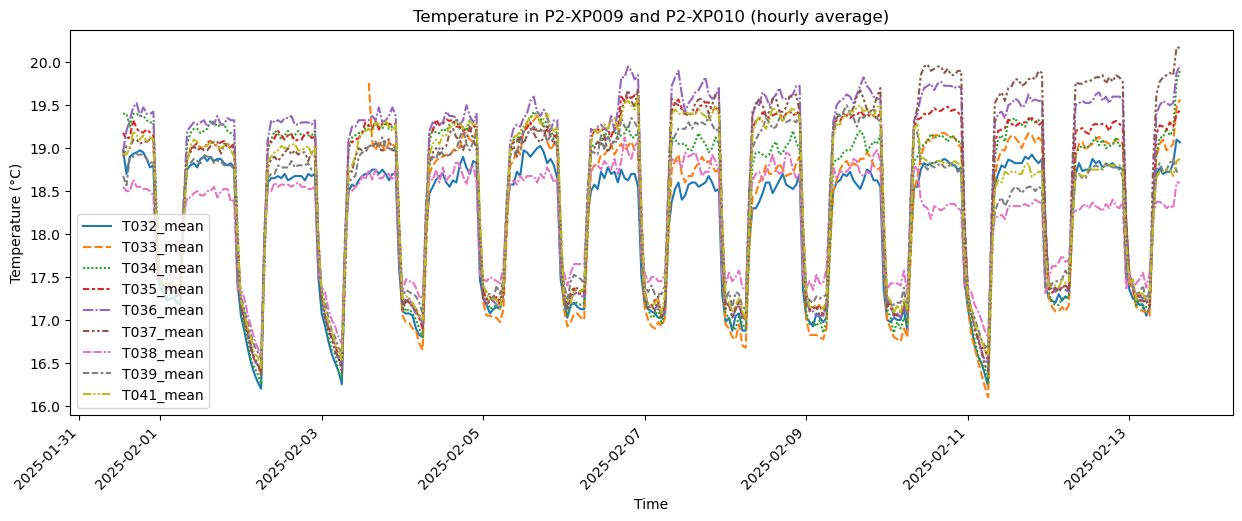

In [ ]:
# Plot temperatures when column names contain T
temp_df = temp_hygro_hourly_average.filter(regex='T', axis=1)

plt.figure(figsize=(15, 5))
sns.lineplot(data=temp_df)
plt.title(args.ttitle)')
plt.ylabel('Temperature (°C)')
plt.xlabel('Time')
plt.xticks(rotation=45, ha='right')
plt.savefig(args.outdir + 'temperature_hourly_average.png')
plt.show()

# Plot hygrometry

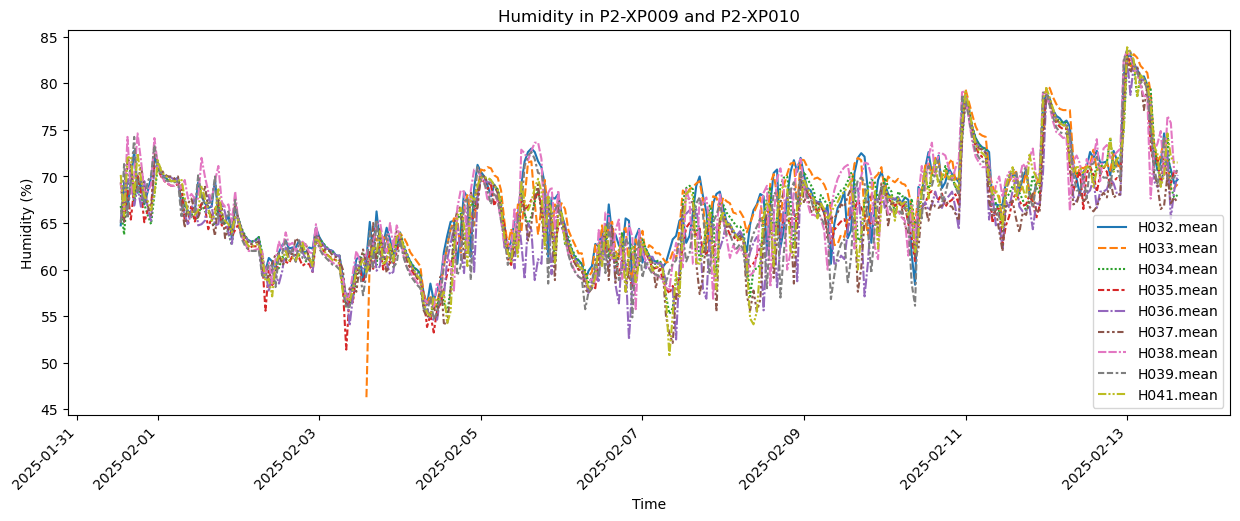

In [ ]:
# Keep humidity data if column names contain H
hygro_df = temp_hygro_hourly_average.filter(regex='H', axis=1)

# Plot
plt.figure(figsize=(15, 5))
sns.lineplot(data=hygro_df)
plt.title('Humidity in P2-XP009 and P2-XP010')
plt.ylabel('Humidity (%)')
plt.xlabel('Time')
plt.xticks(rotation=45, ha='right')

plt.savefig(args.outdir + 'hygrometry_hourly_average.png')

plt.show()

In [4]:
if __name__ == '__main__':
    main()

NameError: name 'main' is not defined